In [1]:
import numpy as np
import pandas as pd
import pickle
import glob
import os
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.fft import fft, ifft, fftfreq
from scipy.ndimage import gaussian_filter1d
#make font size bigger for actual figas to us 
matplotlib.rcParams['font.size'] = 8.0 
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
Fs          = 3e4
TimeHistory = 20e-3
TimePost    = 2e-3
L           = int(TimeHistory * Fs)  # 600 samples

out_path = './dataFolder/Whitened_STA/'
os.makedirs(out_path, exist_ok=True)
out_fig = './dataFolder/Figures/Whitened_STA/'
os.makedirs(out_fig, exist_ok=True)

In [13]:
model_files    = glob.glob('./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/*.pickle')
wn_files       = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_timeStamps_degrees.pickle')
wn_files_scaled = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_timeStamps_scaled.pickle')

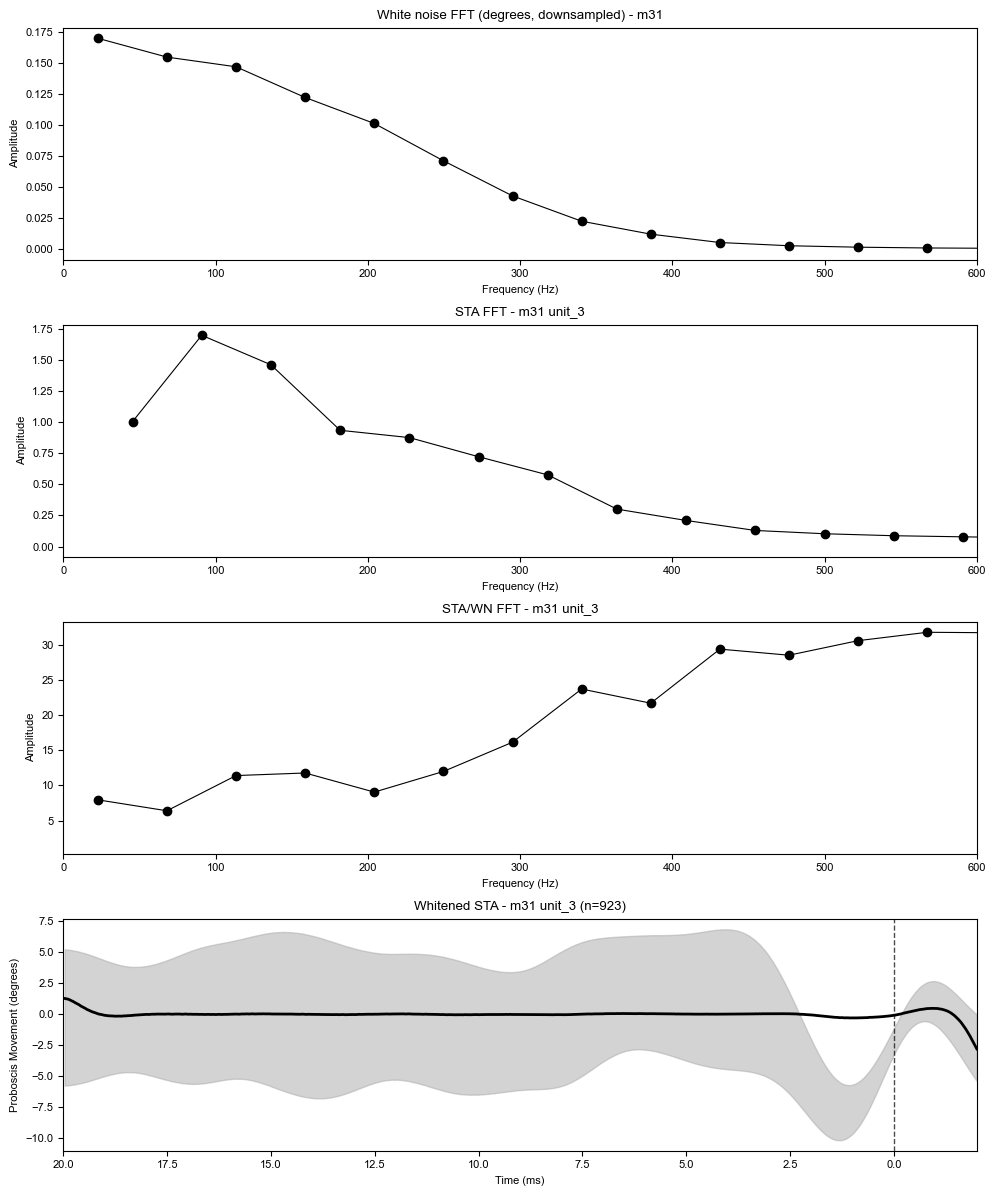

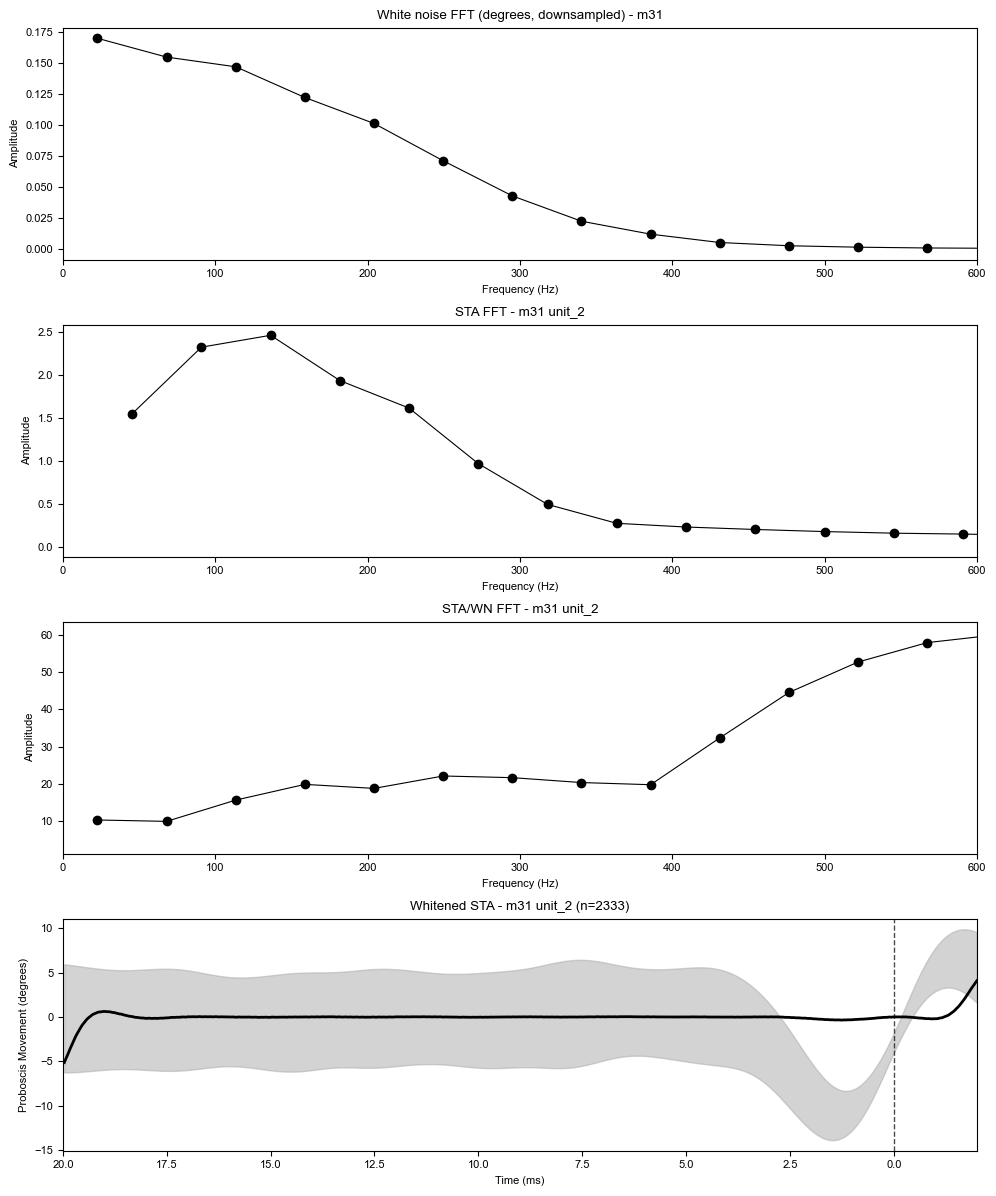

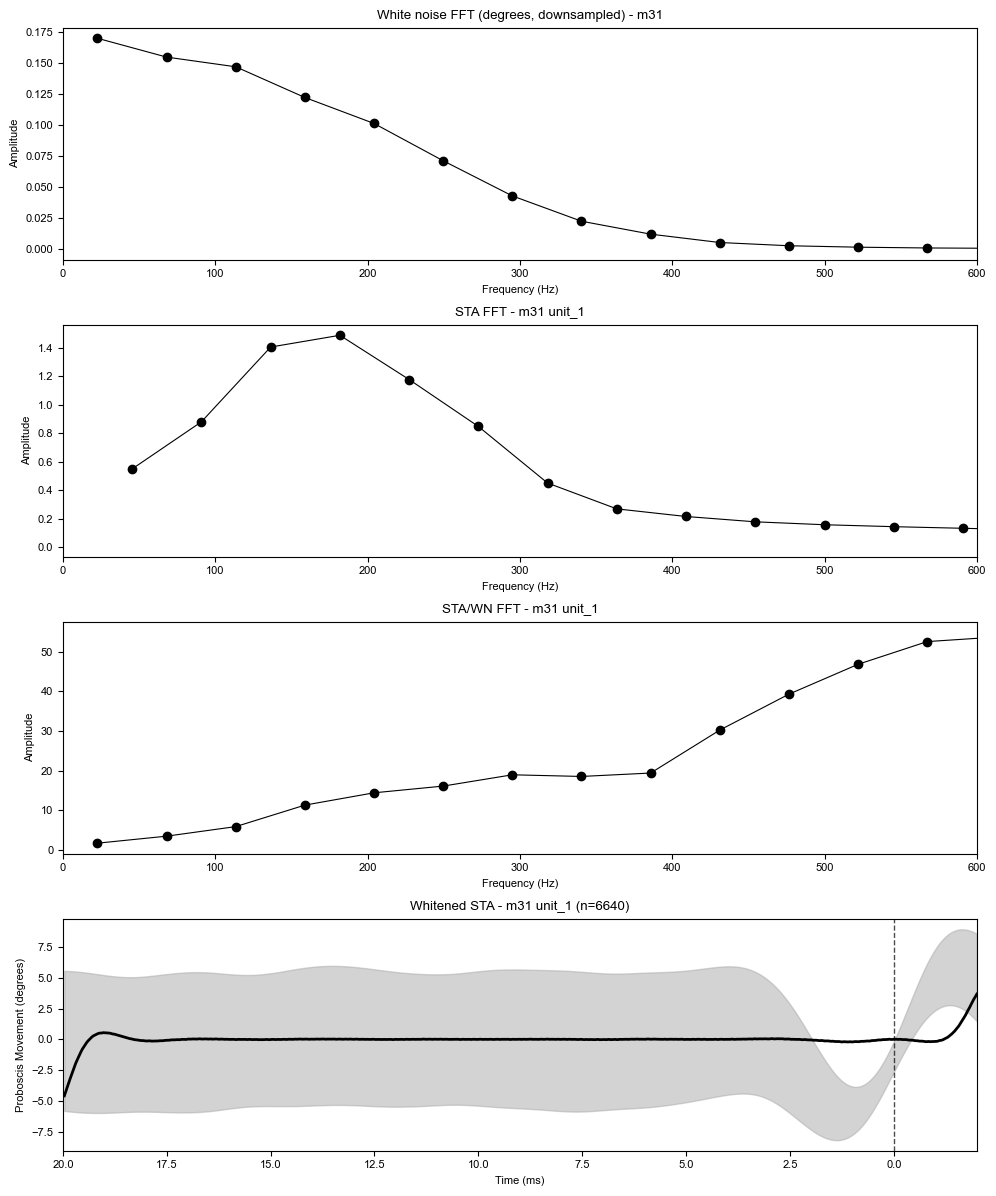

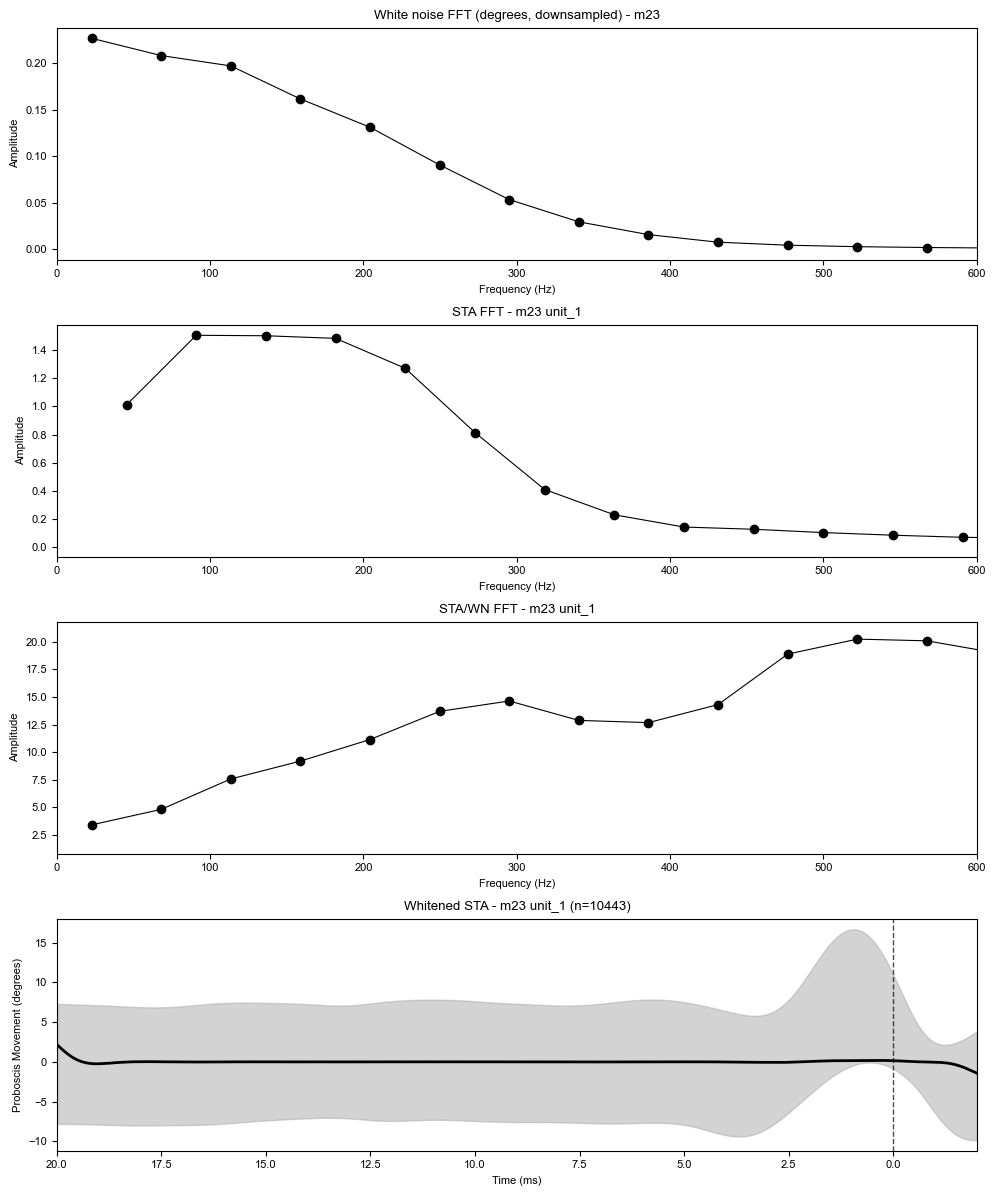

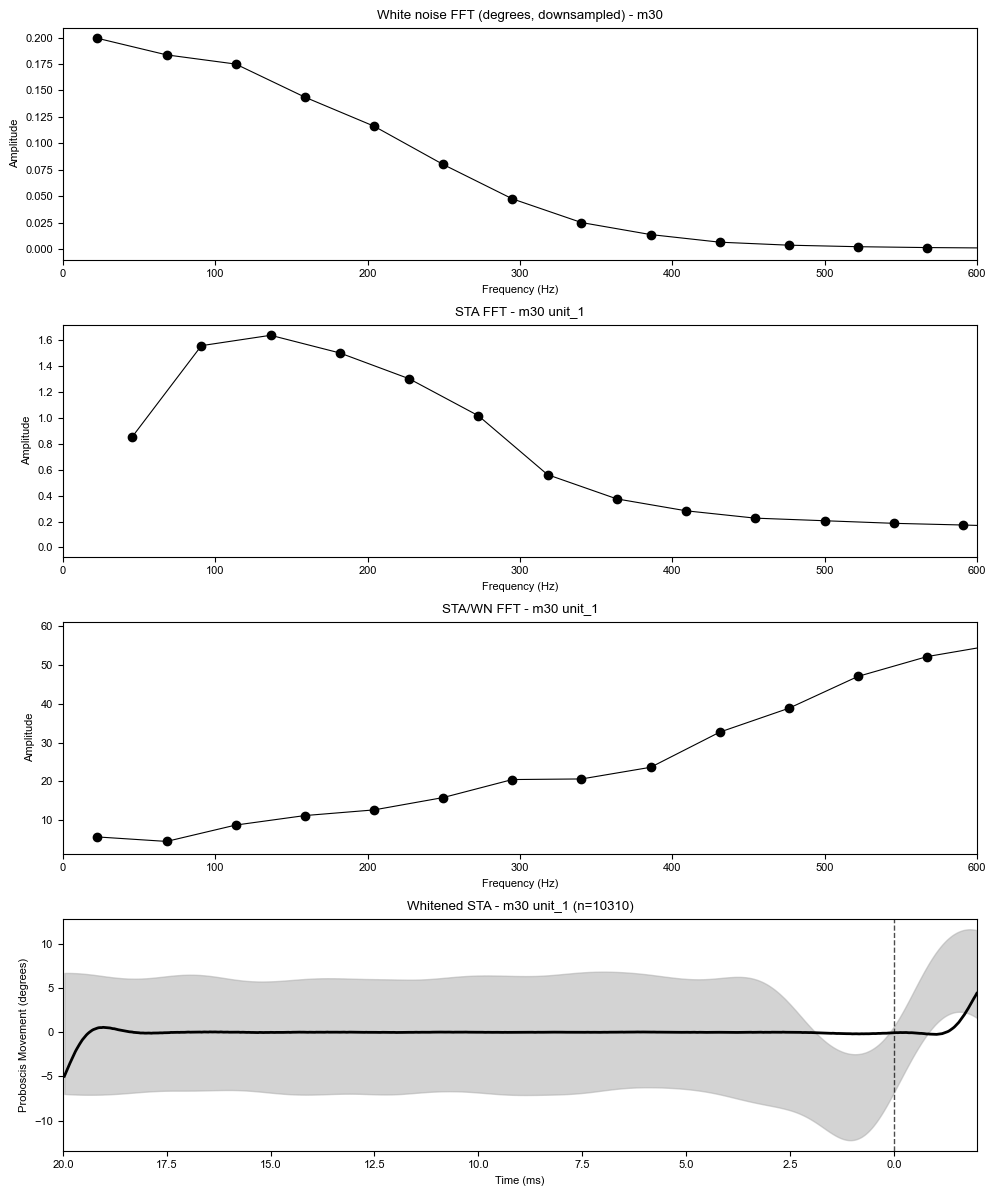

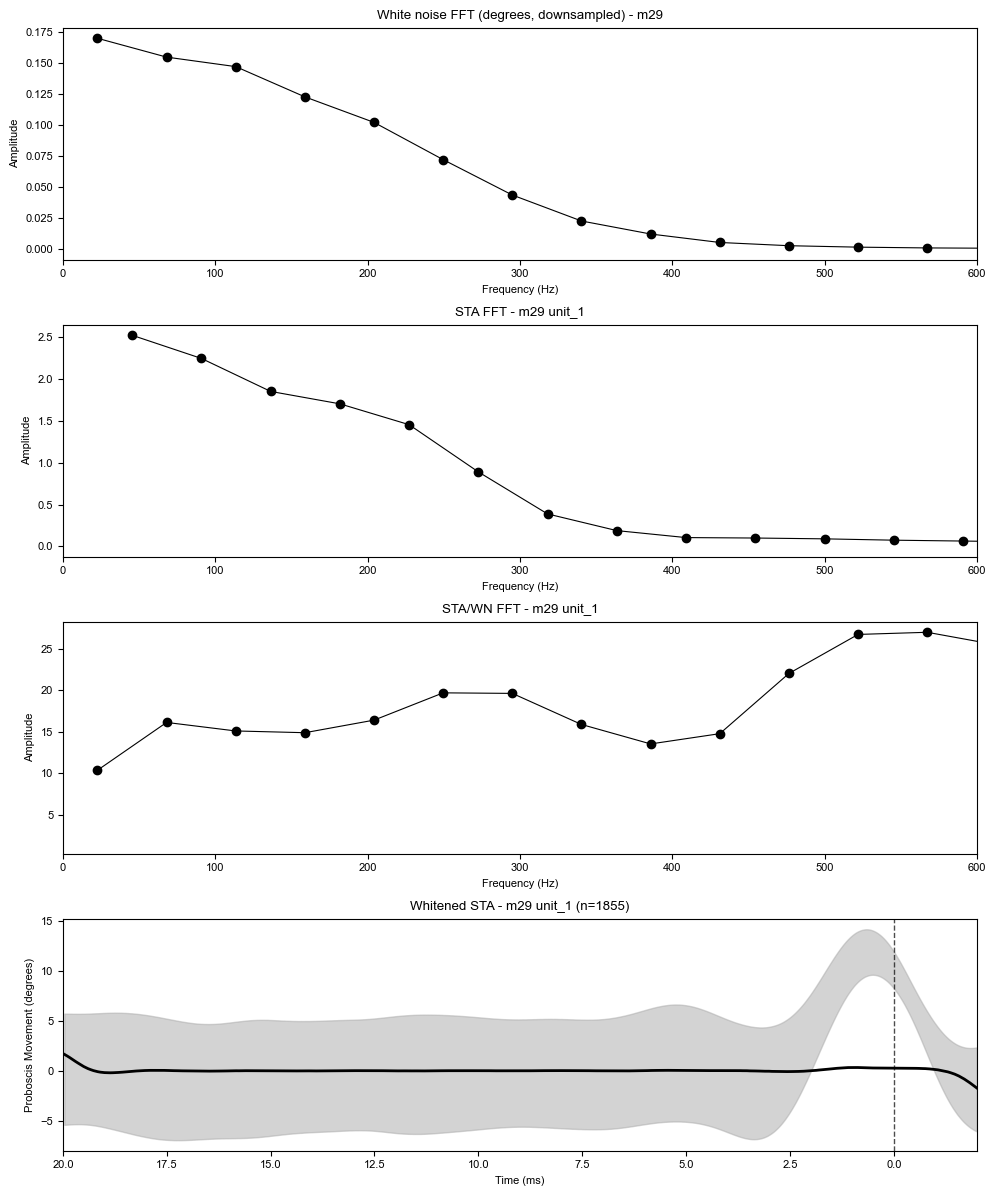

In [14]:
for filepath in model_files:
    name = os.path.basename(filepath).split('_')[0]
    unitID = "_".join(os.path.basename(filepath).split('_')[1:3])
    
    # load STA
    with open(filepath, 'rb') as f:
        savedModel = pickle.load(f)
    sta       = savedModel[1].values
    sta_error = savedModel[2].values
    n_spikes  = len(savedModel[0])
    
    # load matching white noise
    wn_filepath = [f for f in wn_files if name in f][0]
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    # FFT of STA
    freqs_sta = fftfreq(len(sta), d=1/Fs)
    pos_sta   = freqs_sta > 0
    fft_sta   = fft(sta, norm='forward')
    fft_sta  *= 2
    
    # FFT of white noise downsampled to STA resolution
    fft_wn_full  = np.abs(fft(WhiteNoise, norm='forward'))
    fft_wn_full *= 2
    freqs_wn_full = fftfreq(len(WhiteNoise), d=1/Fs)
    chunk        = len(fft_wn_full) // len(sta)
    fft_wn_ds    = np.array([fft_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(len(sta))])
    freqs_wn_ds  = np.array([freqs_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(len(sta))])
    pos          = freqs_wn_ds > 0
    
    # spectral whitening with regularisation, tried without at the sta loses its smoothness
    lambda_reg       = 0.01 * np.max(fft_wn_ds)
    fft_sta_whitened = fft_sta / (fft_wn_ds + lambda_reg)
    
    # inverse FFT
    sta_whitened = np.real(ifft(fft_sta_whitened))
    
    # plot all 4 panels
    fig, axes = plt.subplots(4, 1, figsize=(10, 12))
    
    axes[0].plot(freqs_wn_ds[pos], fft_wn_ds[pos], 'o-k', linewidth=0.8)
    axes[0].set_ylabel('Amplitude')
    axes[0].set_xlim(0, 600)
    axes[0].set_title(f'White noise FFT (degrees, downsampled) - {name}')
    
    axes[1].plot(freqs_sta[pos_sta], np.abs(fft_sta)[pos_sta], 'o-k', linewidth=0.8)
    axes[1].set_ylabel('Amplitude')
    axes[1].set_xlim(0, 600)
    axes[1].set_title(f'STA FFT - {name} {unitID}')
    
    axes[2].plot(freqs_wn_ds[pos], np.abs(fft_sta_whitened)[pos], 'o-k', linewidth=0.8)
    axes[2].set_ylabel('Amplitude')
    axes[2].set_xlim(0, 600)
    axes[2].set_title(f'STA/WN FFT - {name} {unitID}')
    
    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs) * 1000
    axes[3].fill_between(time_axis, np.flip(sta - sta_error, axis=0), np.flip(sta + sta_error, axis=0),
                         color='darkgrey', alpha=0.5)
    axes[3].plot(time_axis, np.flip(sta_whitened), 'k', linewidth=2)
    axes[3].axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
    axes[3].set_xlim(20, -2)
    axes[3].set_xlabel('Time (ms)')
    axes[3].set_ylabel('Proboscis Movement (degrees)')
    axes[3].set_title(f'Whitened STA - {name} {unitID} (n={n_spikes})')
    
    for ax in axes[:3]:
        ax.set_xlabel('Frequency (Hz)')
    
    plt.tight_layout()
    #plt.savefig(out_fig + name + '_' + unitID + '_whitening_summary.pdf')
    plt.show()
    plt.close()

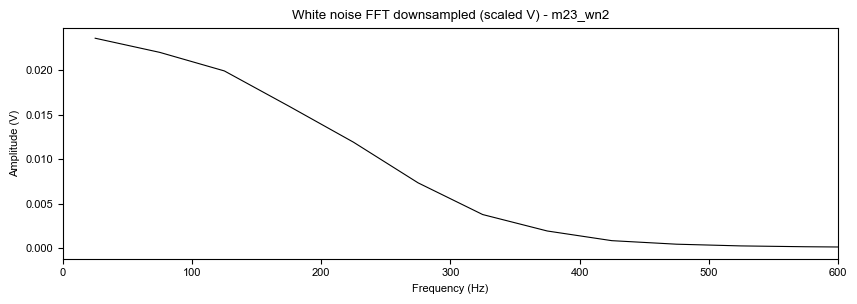

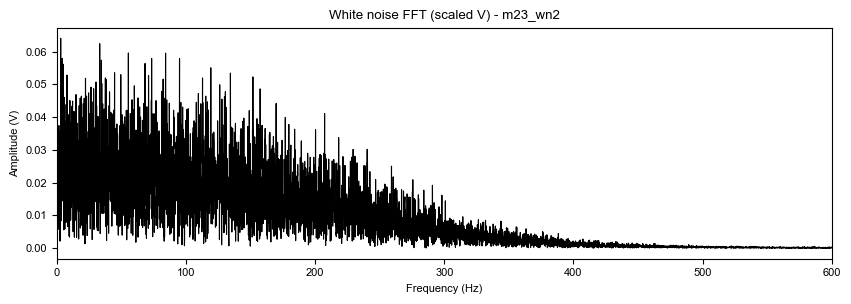

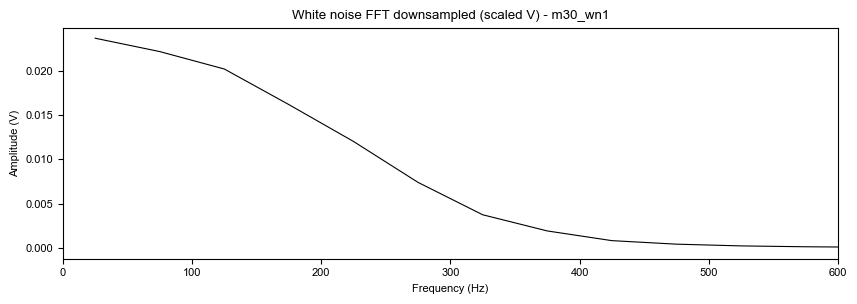

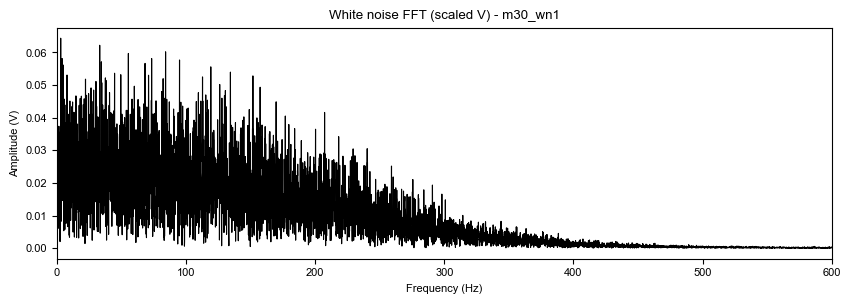

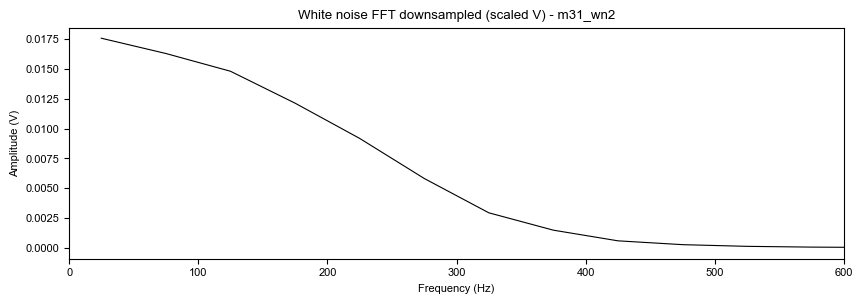

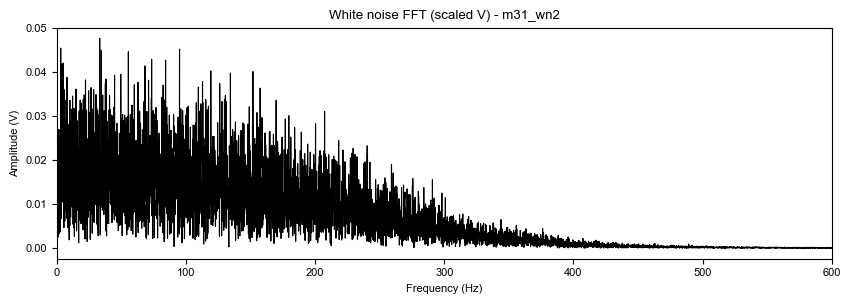

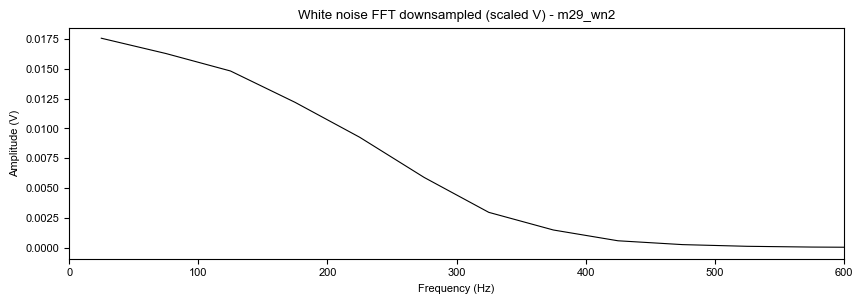

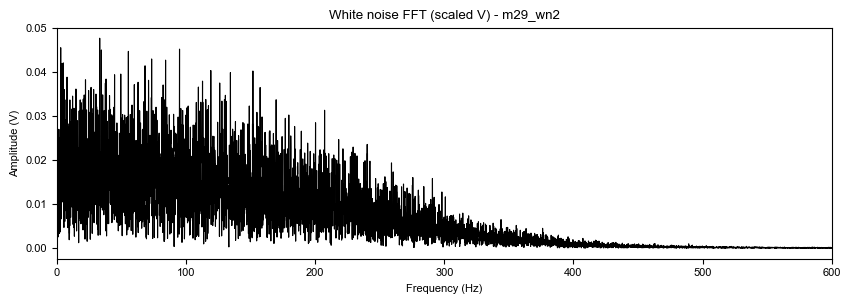

In [25]:
#FFT of raw scaled white noise- hasn't been downsampled. just to see the amplitude of the waveform
for wn_filepath in wn_files_scaled:
    name = '_'.join(os.path.basename(wn_filepath).split('_')[0:2])
    
    if not any(name.split('_')[0] in f for f in [os.path.basename(m).split('_')[0] for m in model_files]):
        continue
    
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    fft_wn_full = np.abs(fft(WhiteNoise)) / len(WhiteNoise) * 2
    freqs_wn_full = fftfreq(len(WhiteNoise), d=1/Fs)
    pos = freqs_wn_full > 0

    # downsampled to match sta when i want 
    # chunk = len(fft_wn_full) // L
    # fft_wn_ds = np.array([fft_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(L)])
    # freqs_wn_ds = np.array([freqs_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(L)])
    # pos_ds = freqs_wn_ds > 0

    # # downsampled plot - i can comment this out whenever to chose which one 
    # plt.figure(figsize=(10, 3))
    # plt.plot(freqs_wn_ds[pos_ds], fft_wn_ds[pos_ds], 'o-k', linewidth=0.8)
    # plt.xlabel('Frequency (Hz)')
    # plt.ylabel('Amplitude (V)')
    # plt.xlim(0, 600)
    # plt.title(f'White noise FFT downsampled (scaled V) - {name}')
    # #plt.savefig(out_fig + name + '_WN_fft_scaledV_ds.pdf')
    # plt.show()
    # plt.close()
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_wn_full[pos], fft_wn_full[pos], 'k', linewidth=0.8)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude (V)')
    plt.xlim(0, 600)
    plt.title(f'White noise FFT (scaled V) - {name}')
    #plt.savefig(out_fig + name + '_WN_fft_scaledV.pdf')
    plt.show()
    plt.close()

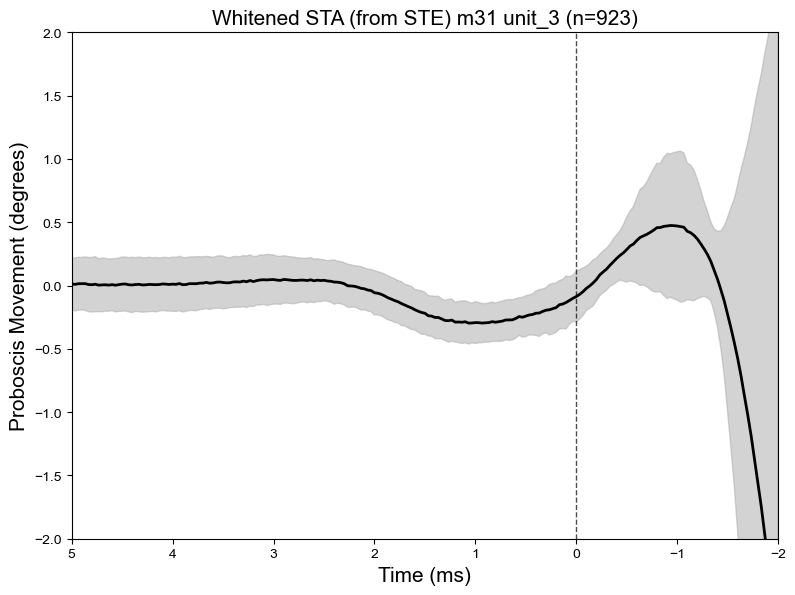

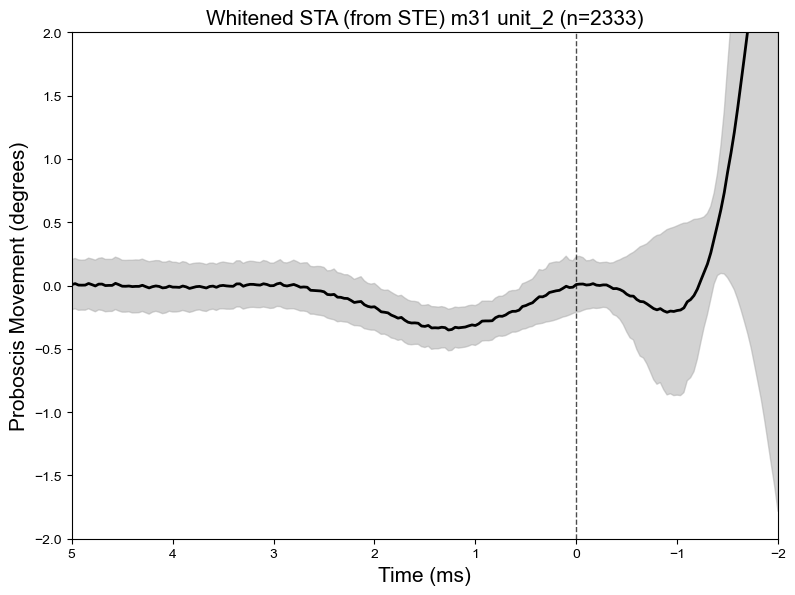

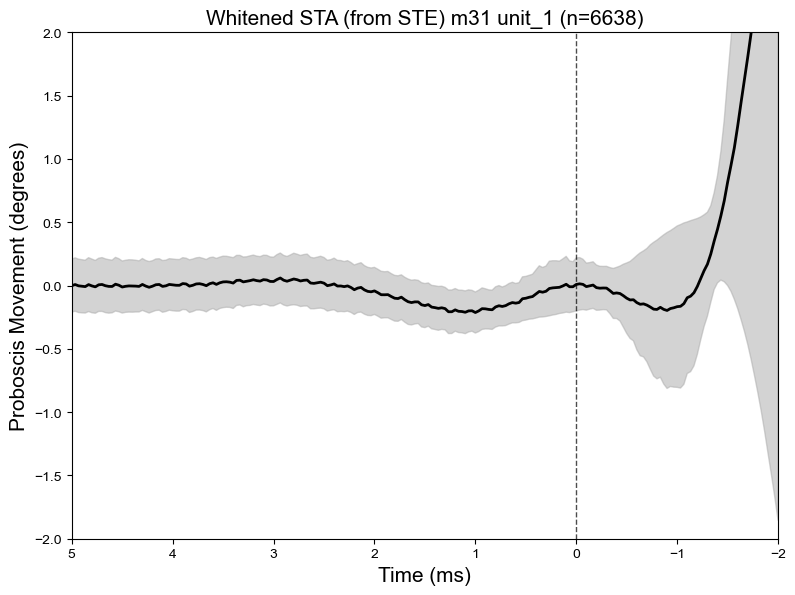

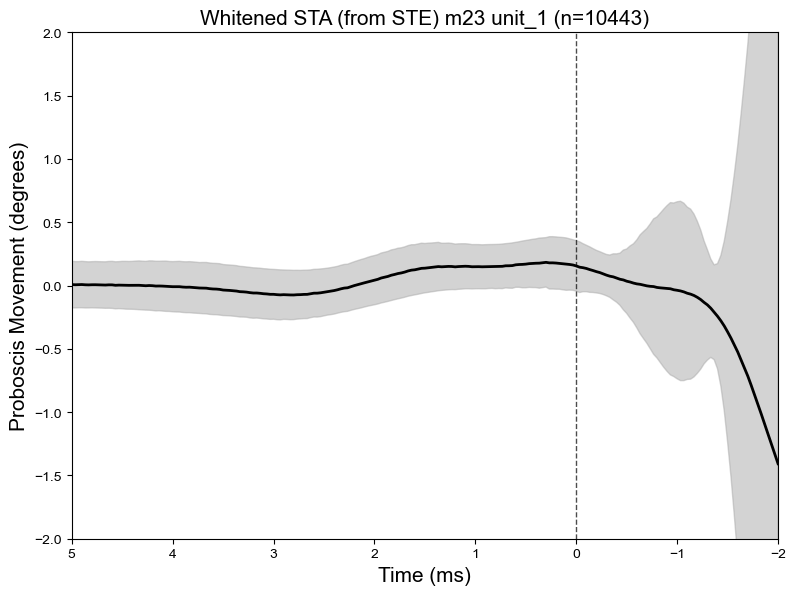

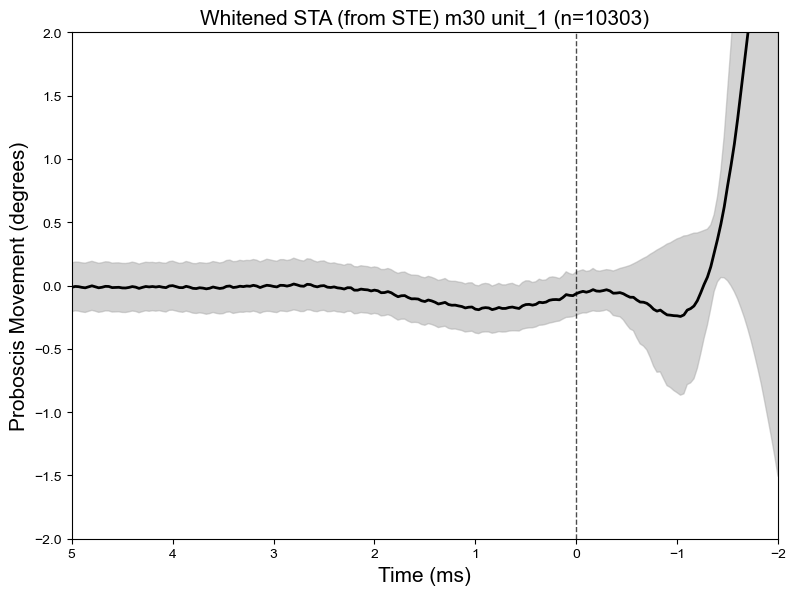

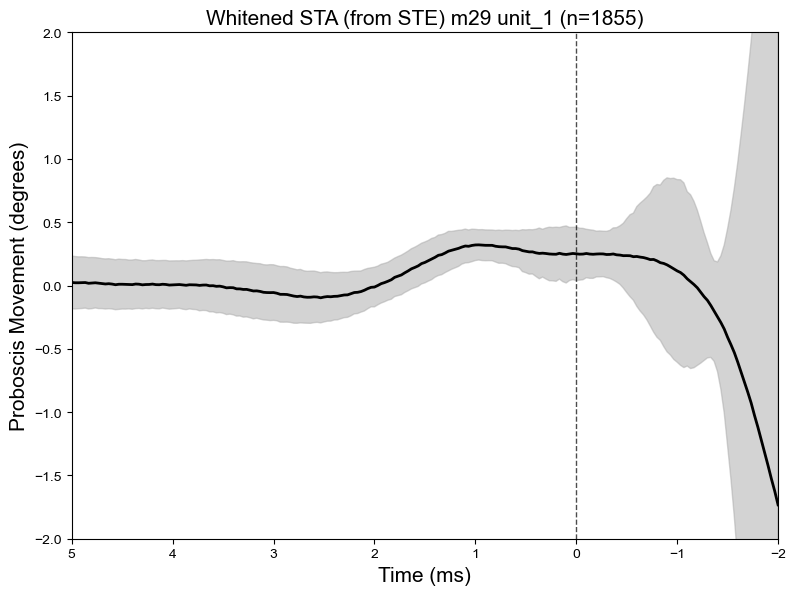

In [27]:
for filepath in model_files:
    name = os.path.basename(filepath).split('_')[0]
    unitID = "_".join(os.path.basename(filepath).split('_')[1:3])
    
    with open(filepath, 'rb') as f:
        savedModel = pickle.load(f)
    ste = savedModel[0].dropna()
    n_spikes = len(ste)
    
    wn_filepath = [f for f in wn_files if name in f][0]
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    # white noise FFT downsampled to snippet length= madeb it 660 here also
    snippet_len = ste.shape[1]
    fft_wn_full = np.abs(fft(WhiteNoise, norm='forward')) * 2
    chunk = len(fft_wn_full) // snippet_len
    fft_wn_ds = np.array([fft_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(snippet_len)])
    lambda_reg = 0.01 * np.max(fft_wn_ds)
    
    # whiten each snippet of ste then average and get sta
    whitened_snippets = []
    for i in range(n_spikes):
        snippet = ste.iloc[i].values
        fft_snippet = fft(snippet, norm='forward') * 2
        fft_whitened = fft_snippet / (fft_wn_ds + lambda_reg)
        whitened_snippets.append(np.real(ifft(fft_whitened)))
    
    sta_whitened = np.mean(whitened_snippets, axis=0)
    sta_error    = np.std(whitened_snippets, axis=0)
    
    
    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs) * 1000
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.fill_between(time_axis, np.flip(sta_whitened - sta_error), np.flip(sta_whitened + sta_error),
                    color='darkgrey', alpha=0.5)
    ax.plot(time_axis, np.flip(sta_whitened), 'k', linewidth=2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax.set_xlim(5, -2)
    ax.set_ylim(-2,2)
    ax.set_xlabel('Time (ms)', fontsize=15)
    ax.set_ylabel('Proboscis Movement (degrees)', fontsize=15)
    ax.set_title(f'Whitened STA (from STE) {name} {unitID} (n={n_spikes})', fontsize=15)
    ax.tick_params(labelsize=10)
    plt.tight_layout()
    #plt.savefig(out_fig + name + '_' + unitID + '_STEWhitenedSTA.pdf')
    plt.show()
    plt.close()